# Profiling

**Seong Cho** · ACME Python Essentials, Lab 9

**Lab objective:** measure the complexity and efficiency of a program to see which parts need optimizing, and learn common techniques for speeding up Python code, including the built-in profiler and the Numba module.

<sub>Lab specification from the *Python Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

> **Note.** Timings depend on the machine, so the numbers printed below differ from the spec's (and from run to run). The spec's own timings are quoted as written for comparison. A few of the spec's slowest demonstrations are run at a smaller size here, as noted where they occur, and `%timeit -r 3` (3 repeats instead of the default 7) shortens the timing of the slowest functions.

In [1]:
import time
import numpy as np
from matplotlib import pyplot as plt

## Magic Commands in IPython

IPython's "magic commands" time and profile code quickly. They start with one `%` to test a single line or two (`%%`) to test a whole cell.

- `%time`: execute some code and print its execution time.
- `%timeit`: execute some code several times and print the average execution time.
- `%prun`: run a statement through the Python code profiler (a shortcut for `cProfile.run()`; see https://docs.python.org/3/library/profile.html), printing the number of function calls and the time each takes.

The spec times building a list of squares with a comprehension (wall time 40.9 ms) and with a regular `for` loop (55.2 ms): the list comprehension is faster.

In [2]:
%time x = [i**2 for i in range(int(1e5))]

CPU times: user 4.5 ms, sys: 35.3 ms, total: 39.8 ms
Wall time: 2.46 ms


In [3]:
%%time
# A double %% times the whole cell.
x = []
for i in range(int(1e5)):
    x.append(i**2)

CPU times: user 7.8 ms, sys: 64.2 ms, total: 72 ms
Wall time: 4.45 ms


## Choosing Faster Algorithms

The best way to speed up a program is to use an efficient algorithm. A bad algorithm, even when implemented well, is never an adequate substitute for a good algorithm.

## Problem 1: Maximum path sum

> **Problem 1.** This problem comes from https://projecteuler.net (problems 18 and 67).
>
> By starting at the top of the triangle below and moving to adjacent numbers on the row below, the maximum total from top to bottom is 23.
>
> ```text
>    3
>   7 4
>  2 4 6
> 8 5 9 3
> ```
>
> That is, $3 + 7 + 4 + 9 = 23$.
>
> The following function finds the maximum path sum of the triangle in `triangle.txt` by recursively computing the sum of every possible path—the "brute force" approach. *[`max_path()` as given; it is the first function in the code cell below.]*
>
> The data in `triangle.txt` contains 15 rows and hence 16384 paths, so it is possible to solve this problem by trying every route. However, for a triangle with 100 rows, there are $2^{99}$ paths to check, which would take billions of years to compute even for a program that could check one trillion routes per second. No amount of improvement to `max_path()` can make it run in an acceptable amount of time on such a triangle—we need a different algorithm.
>
> Write a function that accepts a filename containing a triangle of integers. Compute the largest path sum with the following strategy: starting from the next to last row of the triangle, replace each entry with the sum of the current entry and the greater of the two "child entries." Continue this replacement up through the entire triangle. The top entry in the triangle will be the maximum path sum. In other words, work from the bottom instead of from the top.
>
> ```text
>    3              3              3             23
>   7 4            7 4           20 19         20 19
>  2 4 6   -->  10 13 15  -->  10 13 15  -->  10 13 15
> 8 5 9 3      8  5  9  3     8  5  9  3     8  5  9  3
> ```
>
> Use your function to find the maximum path sum of the 100-row triangle stored in `triangle_large.txt`. Make sure that your new function still gets the correct answer for the smaller `triangle.txt`. Finally, use `%time` or `%timeit` to time both functions on `triangle.txt`. Your new function should be about 100 times faster than the original.

`max_path_fast()` updates the triangle in place from the second-to-last row upward, so it is linear in the number of entries.

In [4]:
def max_path(filename="triangle.txt"):
    """Find the maximum vertical path in a triangle of values."""
    with open(filename, 'r') as infile:
        data = [[int(n) for n in line.split()]
                        for line in infile.readlines()]
    def path_sum(r, c, total):
        """Recursively compute the max sum of the path starting in row r
        and column c, given the current total.
        """
        total += data[r][c]
        if r == len(data) - 1:          # Base case.
            return total
        else:                           # Recursive case.
            return max(path_sum(r+1, c,   total),   # Next row, same column
                       path_sum(r+1, c+1, total))   # Next row, next column

    return path_sum(0, 0, 0)            # Start the recursion from the top.

def max_path_fast(filename="triangle_large.txt"):
    """Find the maximum vertical path in a triangle of values."""
    with open(filename, 'r') as infile:
        data = [[int(n) for n in line.split()]
                        for line in infile.readlines()]
    for i in range(len(data) - 2, -1, -1):
        for j in range(len(data[i])):
            data[i][j] += max(data[i+1][j], data[i+1][j+1])
    return data[0][0]

In [5]:
print("triangle.txt:      ", max_path("triangle.txt"), max_path_fast("triangle.txt"))
print("triangle_large.txt:", max_path_fast("triangle_large.txt"))

triangle.txt:       1074 1074
triangle_large.txt: 7273


In [6]:
%timeit -r 3 max_path("triangle.txt")
%timeit max_path_fast("triangle.txt")

1.55 ms ± 15.4 μs per loop (mean ± std. dev. of 3 runs, 1,000 loops each)


21.5 μs ± 482 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


## The Profiler

`%prun` lists the functions called while running a piece of code, along with:

| Heading | Description |
|---|---|
| primitive calls | The number of calls that were not caused by recursion. |
| ncalls | The number of calls to the function. If recursion occurs, the output is `<total number of calls>/<number of primitive calls>`. |
| tottime | The amount of time spent in the function, not including calls to other functions. |
| percall | The amount of time spent in each call of the function. |
| cumtime | The amount of time spent in the function, including calls to other functions. |

`%prun` normally sends its report to IPython's pager, which a saved notebook doesn't keep. The first cell below routes the pager to ordinary cell output so the reports are saved with the notebook.

In [7]:
from IPython.core import page
page.page = lambda data, *args, **kwargs: print(data if isinstance(data, str) else data["text/plain"])

In [8]:
%prun max_path("triangle.txt")

         82354 function calls (49583 primitive calls) in 0.007 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
  32767/1    0.005    0.000    0.007    0.007 1147083602.py:6(path_sum)
    32775    0.001    0.000    0.001    0.000 {built-in method builtins.len}
    16385    0.001    0.000    0.001    0.000 {built-in method builtins.max}
        1    0.000    0.000    0.000    0.000 base_events.py:1970(_run_once)
        4    0.000    0.000    0.000    0.000 attrsettr.py:66(_get_attr_opt)
       14    0.000    0.000    0.000    0.000 socket.py:623(send)
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}
      2/1    0.000    0.000    0.007    0.007 {built-in method builtins.exec}
        1    0.000    0.000    0.000    0.000 {method 'readlines' of '_io._IOBase' objects}
       60    0.000    0.000    0.000    0.000 enum.py:1589(_get_value)
        1    0.000    0.000    0.007    0.00

## Optimizing Python Code

A poor implementation of a good algorithm is better than a good implementation of a bad algorithm, but clumsy implementation can still cripple a program's efficiency. The practices below help, though they are futile if the algorithm is poorly suited for the problem.

### Avoid repetition

A clean program does no more work than necessary, and the `ncalls` column is especially useful for spotting repetition. The profile of `max_path()` shows `len()` called 32,767 times, exactly as often as `path_sum()`. The easy fix is to save `len(data)` in a variable outside `path_sum()`:

In [9]:
def max_path_clean(filename="triangle.txt"):
    with open(filename, 'r') as infile:
        data = [[int(n) for n in line.split()]
                        for line in infile.readlines()]
    N = len(data)                       # Calculate len(data) outside of path_sum().
    def path_sum(r, c, total):
        total += data[r][c]
        if r == N - 1:                  # Use N instead of len(data).
            return total
        else:
            return max(path_sum(r+1, c, total),
                       path_sum(r+1, c+1, total))
    return path_sum(0, 0, 0)

In [10]:
%prun max_path_clean("triangle.txt")

         49588 function calls (16817 primitive calls) in 0.005 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
  32767/1    0.004    0.000    0.005    0.005 1923773892.py:6(path_sum)
    16385    0.001    0.000    0.001    0.000 {built-in method builtins.max}
        1    0.000    0.000    0.000    0.000 base_events.py:1970(_run_once)
        4    0.000    0.000    0.000    0.000 attrsettr.py:66(_get_attr_opt)
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}
       14    0.000    0.000    0.000    0.000 socket.py:623(send)
       60    0.000    0.000    0.000    0.000 enum.py:1589(_get_value)
        1    0.000    0.000    0.000    0.000 {built-in method _io.open}
      2/1    0.000    0.000    0.005    0.005 {built-in method builtins.exec}
        1    0.000    0.000    0.005    0.005 1923773892.py:1(max_path_clean)
        2    0.000    0.000    0.000    0.000 socket.py:771(re

In the spec, the total number of primitive function calls dropped from 49,181 to 16,415, and `%timeit` showed a run time about 15% lower. Moving code outside of a loop or an often-used function usually gives a similar speedup.

Carefully controlling loop conditions also avoids unnecessary iterations. To find Pythagorean triples (distinct integers $a < b < c$ with $a^2 + b^2 = c^2$) with entries less than $N$, the slow version checks all possible triples. Since $a < b < c$, any case with $b \le a$ or $c \le b$ is unnecessary, and once $a$ and $b$ are chosen, $c \le \sqrt{a^2 + b^2}$. The fast version changes the loop conditions to skip these cases and computes $a^2 + b^2$ only once for each pair $(a, b)$.

In [11]:
from math import sqrt

def pythagorean_triples_slow(N):
    """Compute all pythagorean triples with entries less than N."""
    triples = []
    for a in range(1, N):               # Try values of a from 1 to N-1.
        for b in range(1, N):           # Try values of b from 1 to N-1.
            for c in range(1, N):       # Try values of c from 1 to N-1.
                if a**2 + b**2 == c**2 and a < b < c:
                    triples.append((a,b,c))
    return triples

def pythagorean_triples_fast(N):
    """Compute all pythagorean triples with entries less than N."""
    triples = []
    for a in range(1, N):               # Try values of a from 1 to N-1.
        for b in range(a+1, N):         # Try values of b from a+1 to N-1.
            _sum = a**2 + b**2
            for c in range(b+1, min(int(sqrt(_sum))+1, N)):
                if _sum == c**2:
                    triples.append((a,b,c))
    return triples

The spec timed both with $N = 500$: 1 min 52 s for the slow version and 1.57 s for the fast one ("98.6% faster!").

In [12]:
%time triples = pythagorean_triples_slow(500)
%time triples = pythagorean_triples_fast(500)

CPU times: user 5.23 s, sys: 23.3 ms, total: 5.25 s
Wall time: 5.26 s
CPU times: user 92.4 ms, sys: 279 μs, total: 92.7 ms
Wall time: 92.7 ms


## Problem 2: Faster primes

> **Problem 2.** The following function computes the first $N$ prime numbers. *[`primes()` as given; it is the first function in the code cell below.]*
>
> This function takes about 6 minutes to find the first 10,000 primes on a fast computer. Without significantly modifying the approach, rewrite `primes()` so that it can compute 10,000 primes in under 0.1 seconds. Use the following facts to reduce unnecessary iterations.
> - A number is not prime if it has one or more divisors other than 1 and itself.
>   (Hint: recall the `break` statement.)
> - If $p \nmid n$, then $ap \nmid n$ for any integer $a$. Also, if $p \mid n$ and $0 < p < n$, then $p \le \sqrt{n}$.
> - Except for 2, primes are always odd.
>
> Your new function should be helpful for solving problem 7 on https://projecteuler.net.

`primes_fast()` tries only odd candidates, divides only by the primes found so far, and stops at the first divisor or once the trial divisor passes $\sqrt{n}$.

In [13]:
def primes(N):
    """Compute the first N primes."""
    primes_list = []
    current = 2
    while len(primes_list) < N:
        isprime = True
        for i in range(2, current):     # Check for nontrivial divisors.
            if current % i == 0:
                isprime = False
        if isprime:
            primes_list.append(current)
        current += 1
    return primes_list

def primes_fast(N):
    """Compute the first N primes."""
    primes_list = [2]
    current = 3
    while len(primes_list) < N:
        S = int(np.sqrt(current))
        isprime = True
        for i in primes_list:
            if current % i == 0:
                isprime = False
                break
            if i > S:
                break
        if isprime:
            primes_list.append(current)
        current += 2
    return primes_list

The original `primes()` is timed for the first 1,000 primes rather than 10,000 (the spec's "about 6 minutes"); its run time grows roughly quadratically, so even that is slow. `primes_fast()` is timed at the full 10,000.

In [14]:
print(primes(1000) == primes_fast(1000), primes_fast(10000)[-3:])
%time p = primes(1000)
%timeit primes_fast(10000)

True [104717, 104723, 104729]


CPU times: user 544 ms, sys: 2.23 ms, total: 547 ms
Wall time: 547 ms


37.4 ms ± 287 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


### Avoid loops

NumPy routines and built-in functions can often eliminate loops altogether. Summing the rows of a matrix three ways:

In [15]:
def row_sum_awful(A):
    """Sum the rows of A by iterating through rows and columns."""
    m,n = A.shape
    row_totals = np.empty(m)            # Allocate space for the output.
    for i in range(m):                  # For each row...
        total = 0
        for j in range(n):              # ...iterate through the columns.
            total += A[i,j]
        row_totals[i] = total           # Record the total.
    return row_totals

def row_sum_bad(A):
    """Sum the rows of A by iterating through rows."""
    return np.array([sum(A[i,:]) for i in range(A.shape[0])])

def row_sum_fast(A):
    """Sum the rows of A with NumPy."""
    return np.sum(A, axis=1)            # Or A.sum(axis=1).

The spec used a $10000 \times 10000$ matrix (an 800 MB array) and measured 23.2 s, 8.89 s, and 64 ms. A $2000 \times 2000$ matrix (25 times smaller) shows the same pattern here.

In [16]:
A = np.random.random((2000, 2000))
%time rows = row_sum_awful(A)
%time rows = row_sum_bad(A)
%time rows = row_sum_fast(A)

CPU times: user 206 ms, sys: 1 ms, total: 207 ms
Wall time: 207 ms
CPU times: user 108 ms, sys: 1.55 ms, total: 110 ms
Wall time: 111 ms
CPU times: user 489 μs, sys: 22 μs, total: 511 μs
Wall time: 513 μs


`row_sum_fast()` runs several hundred times faster than `row_sum_awful()`, mainly because looping is expensive in Python, while NumPy handles loops in C. Other NumPy functions with an `axis` argument can often remove loops the same way.

## Problem 3: Nearest column without loops

> **Problem 3.** Let $A$ be an $m \times n$ matrix with columns $\mathbf{a}_0, \ldots, \mathbf{a}_{n-1}$, and let $\mathbf{x}$ be a vector of length $m$. The *nearest neighbor problem*¹ is to determine which of the columns of $A$ is "closest" to $\mathbf{x}$ with respect to some norm. That is, we compute
>
> $$\underset{j}{\operatorname{argmin}}\ \|\mathbf{a}_j - \mathbf{x}\|.$$
>
> The following function solves this problem naïvely for the usual Euclidean norm. *[`nearest_column()` as given; it is the first function in the code cell below.]*
>
> Write a new version of this function without any loops or list comprehensions, using array broadcasting and the `axis` keyword in `np.linalg.norm()` to eliminate the existing loop. Try to implement the entire function in a single line.
> (Hint: See the NumPy Visual Guide in the Appendix for a refresher on array broadcasting.)
>
> Profile the old and new versions with `%prun` and compare the output. Finally, use `%time` or `%timeit` to verify that your new version runs faster than the original.
>
> ¹ The nearest neighbor problem is a common problem in many fields of artificial intelligence. The problem can be solved more efficiently with a k-d tree, a specialized data structure for storing high-dimensional data.

Reshaping $\mathbf{x}$ into an $(m, 1)$ column lets `A - x` broadcast across all $n$ columns at once, and `axis=0` takes the norm of each column.

In [17]:
def nearest_column(A, x):
    """Find the index of the column of A that is closest to x.

    Parameters:
        A ((m,n) ndarray)
        x ((m, ) ndarray)

    Returns:
        (int): The index of the column of A that is closest in norm to x.
    """
    distances = []
    for j in range(A.shape[1]):
        distances.append(np.linalg.norm(A[:,j] - x))
    return np.argmin(distances)

def nearest_column_fast(A, x):
    """Find the index of the column of A that is closest in norm to x.
    Refrain from using any loops or list comprehensions.

    Parameters:
        A ((m,n) ndarray)
        x ((m, ) ndarray)

    Returns:
        (int): The index of the column of A that is closest in norm to x.
    """
    return np.argmin(np.linalg.norm(A - x.reshape((len(x),1)), axis=0))

In [18]:
A = np.random.random((100, 5000))
x = np.random.random(100)
print(nearest_column(A, x), nearest_column_fast(A, x))

4292 4292


The original calls `np.linalg.norm()` once per column (5,000 times here); the new version calls it once. Profiles limited to the top 6 lines (`-l 6`):

In [19]:
%prun -l 6 nearest_column(A, x)

         45188 function calls (45184 primitive calls) in 0.014 seconds

   Ordered by: internal time
   List reduced from 59 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
     5000    0.005    0.000    0.005    0.000 {method 'dot' of 'numpy.ndarray' objects}
5001/5000    0.004    0.000    0.010    0.000 _linalg.py:2623(norm)
      2/1    0.002    0.001    0.008    0.008 817966135.py:1(nearest_column)
        1    0.001    0.001    0.005    0.005 iostream.py:278(_really_send)
     5000    0.000    0.000    0.000    0.000 {method 'ravel' of 'numpy.ndarray' objects}
     5000    0.000    0.000    0.001    0.000 _linalg.py:187(isComplexType)
 

In [20]:
%prun -l 6 nearest_column_fast(A, x)

         425 function calls (420 primitive calls) in 0.001 seconds

   Ordered by: internal time
   List reduced from 81 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.000    0.000 _linalg.py:2623(norm)
      2/1    0.000    0.000    0.001    0.001 {built-in method builtins.exec}
        1    0.000    0.000    0.001    0.001 817966135.py:16(nearest_column_fast)
        1    0.000    0.000    0.000    0.000 {method 'reduce' of 'numpy.ufunc' objects}
        4    0.000    0.000    0.000    0.000 attrsettr.py:66(_get_attr_opt)
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}
 

In [21]:
%timeit -r 3 nearest_column(A, x)
%timeit nearest_column_fast(A, x)

4.53 ms ± 47.7 μs per loop (mean ± std. dev. of 3 runs, 100 loops each)


641 μs ± 61.3 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


### Use data structures correctly

Every data structure has strengths and weaknesses, and choosing the wrong one can be costly.

- **Membership testing.** The `in` operator is near instantaneous with sets and dictionaries, but not with lists. (The spec measured 413 ms per lookup in a 10-million-entry list and 170 ns in the equivalent set.)

In [22]:
a_list = list(range(int(1e7)))
a_set = set(a_list)
%timeit -r 3 12.5 in a_list
%timeit 12.5 in a_set
del a_list, a_set

65.4 ms ± 640 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)


82.8 ns ± 0.836 ns per loop (mean ± std. dev. of 7 runs, 10,000,000 loops each)


Looking up dictionary values is also almost immediate, so use dictionaries to store calculations to be reused, such as mappings between letters and numbers or common function outputs.

- **Construction with comprehension.** Lists, sets, and dictionaries can all be built with comprehension syntax, which is slightly faster than building the collection in a loop (491 ms vs. 440 ms in the spec) and highly readable.

In [23]:
%%time
# Map the integers to their squares with a loop.
a_dict = {}
for i in range(1000000):
    a_dict[i] = i**2

CPU times: user 33.3 ms, sys: 5.69 ms, total: 39 ms
Wall time: 38.9 ms


In [24]:
%time a_dict = {i:i**2 for i in range(1000000)}

CPU times: user 27.5 ms, sys: 7.02 ms, total: 34.5 ms
Wall time: 34.4 ms


- **Intelligent iteration.** Indexing into lists takes time, so loop over the entries themselves rather than their indices, and use `enumerate()` when both are needed. (The spec measured 107 ms vs. 62.5 ms: "almost twice as fast as indexing!")

In [25]:
a_list = list(range(1000000))

In [26]:
%%time
# Loop over the indices of the list.
for i in range(len(a_list)):
    item = a_list[i]

CPU times: user 23 ms, sys: 71 μs, total: 23.1 ms
Wall time: 23.1 ms


In [27]:
%%time
# Loop over the items in the list.
for item in a_list:
    _ = item

CPU times: user 13.1 ms, sys: 55 μs, total: 13.1 ms
Wall time: 13.1 ms


## Problem 4: Name scores

> **Problem 4.** This is problem 22 from https://projecteuler.net.
>
> Using the rule $A \mapsto 1, B \mapsto 2, \ldots, Z \mapsto 26$, the alphabetical value of a name is the sum of the digits that correspond to the letters in the name. For example, the alphabetic value of "COLIN" is $3 + 15 + 12 + 9 + 14 = 53$.
>
> The following function reads the file `names.txt`, containing over five-thousand first names, and sorts them in alphabetical order. The *name score* of each name in the resulting list is the alphabetic value of the name multiplied by the name's position in the list, starting at 1. "COLIN" is the 938th name alphabetically, so its name score is $938 \times 53 = 49714$. The function returns the total of all the name scores in the file. *[`name_scores()` as given; it is the first function in the code cell below.]*
>
> Rewrite this function—removing repetition, eliminating loops, and using data structures correctly—so that it runs in less than 10 milliseconds on average.

`name_scores_fast()` builds the letter-to-value dictionary once, uses `enumerate()` for the positions (instead of `names.index()`, which searches the list every time), and sums with comprehensions.

In [28]:
def name_scores(filename="names.txt"):
    """Find the total of the name scores in the given file."""
    with open(filename, 'r') as infile:
        names = sorted(infile.read().replace('"', '').split(','))
    total = 0
    for i in range(len(names)):
        name_value = 0
        for j in range(len(names[i])):
            alphabet = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
            for k in range(len(alphabet)):
                if names[i][j] == alphabet[k]:
                    letter_value = k + 1
            name_value += letter_value
        total += (names.index(names[i]) + 1) * name_value
    return total

def name_scores_fast(filename='names.txt'):
    """Find the total of the name scores in the given file."""
    with open(filename, 'r') as infile:
        names = sorted(infile.read().replace('"', '').split(','))
    alphabet = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    alph_dict = {letter:index+1 for index, letter in enumerate(alphabet)}
    return sum([(i+1) * sum([alph_dict[n] for n in name]) for i, name in enumerate(names)])

In [29]:
print(name_scores(), name_scores_fast())
%timeit -r 3 name_scores()
%timeit name_scores_fast()

871198282 871198282


80.6 ms ± 75.8 μs per loop (mean ± std. dev. of 3 runs, 10 loops each)


1.28 ms ± 46.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


### Use generators

A *generator* is an iterator that yields multiple values, one at a time, instead of returning a single value (`range()` is one). Generators can reduce both the run time and the memory use of a routine. A function that builds the whole list of $x_n = x_{n-1} + n$, $x_1 = 1$ computes every value before returning anything, which is a problem when $N$ is large. A generator uses `yield` instead of `return`, and when asked for the next entry it resumes right where it left off.

In [30]:
def sequence_function(N):
    """Return the first N entries of the sequence x_n = x_{n-1} + n."""
    sequence = []
    x = 0
    for n in range(1, N+1):
        x += n
        sequence.append(x)
    return sequence

def sequence_generator(N):
    """Yield the first N entries of the sequence x_n = x_{n-1} + n."""
    x = 0
    for n in range(1, N+1):
        x += n
        yield x                         # "return" a single value.

print(sequence_function(10))
generated = sequence_generator(10)
print(next(generated), next(generated), next(generated))   # Entries one at a time.
print(list(sequence_generator(10)))                         # Or [i for i in sequence_generator(10)].
for entry in sequence_generator(10):                        # Use it in a for loop, like range().
    print(entry, end=' ')

[1, 3, 6, 10, 15, 21, 28, 36, 45, 55]
1 3 6
[1, 3, 6, 10, 15, 21, 28, 36, 45, 55]
1 3 6 10 15 21 28 36 45 55 

Generators can also yield values indefinitely; `enumerate()` then helps track the index $n$ along with the entry $x_n$.

In [31]:
def sequence_generator_forever():
    """Yield the sequence x_n = x_{n-1} + n forever."""
    x = 0
    n = 1
    while True:
        x += n
        n += 1
        yield x                         # "return" a single value.

# Sum the entries of the sequence until the sum exceeds 1000.
total = 0
for i, x in enumerate(sequence_generator_forever()):
    total += x
    if total > 1000:
        print(i)                        # Print the index where the total exceeds.
        break                           # Break out of the for loop to stop iterating.

# Check that 18 terms are required (since i starts at 0 but n starts at 1).
print(sum(sequence_generator(17)), sum(sequence_generator(18)))

17
969 1140


> **Achtung!** In Python 2.7 and earlier, `range()` is not a generator. Instead, it constructs an entire list of values, which is often significantly slower than yielding terms individually as needed. If you are using old versions of Python, use `xrange()`, the equivalent of `range()` in Python 3.0 and later.

## Problem 5: Fibonacci generator

> **Problem 5.** This is problem 25 from https://projecteuler.net.
>
> The *Fibonacci sequence* is defined by the recurrence relation $F_n = F_{n-1} + F_{n-2}$, where $F_1 = F_2 = 1$. The 12th term, $F_{12} = 144$, is the first term to contain three digits.
>
> Write a generator that yields the terms of the Fibonacci sequence indefinitely. Next, write a function that accepts an integer $N$. Use your generator to find the first term in the Fibonacci sequence that contains $N$ digits. Return the index of this term.
> (Hint: a generator can have more than one `yield` statement.)

A term has $N$ digits once integer division by $10^{N-1}$ is nonzero; `enumerate()` counts from 0, so the index is `i+1`.

In [32]:
def fibonacci():
    """Yield the terms of the Fibonacci sequence with F_1 = F_2 = 1."""
    F_1 = 1
    F_2 = 1
    yield F_1
    yield F_2
    while True:
        F = F_2
        F += F_1
        F_1 = F_2
        F_2 = F
        yield F


def fibonacci_digits(N=1000):
    """Return the index of the first term in the Fibonacci sequence with
    N digits.

    Returns:
        (int): The index.
    """
    for i, x in enumerate(fibonacci()):
        if x//10**(N-1) != 0:
            return i+1      # Was print(i+1) then break; the spec asks to return the index.

In [33]:
from itertools import islice
print(list(islice(fibonacci(), 12)))
fibonacci_digits(3), fibonacci_digits(1000)

[1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144]


(12, 4782)

## Problem 6: Sieve of Eratosthenes

> **Problem 6.** The function in Problem 2 could be turned into a prime number generator that yields primes indefinitely, but it is not the only strategy for yielding primes. The *Sieve of Eratosthenes*¹ is a faster technique for finding all of the primes below a certain number.
> 1. Given a cap $N$, start with all of the integers from 2 to $N$.
> 2. Remove all integers that are divisible by the first entry in the list.
> 3. Yield the first entry in the list and remove it from the list.
> 4. Return to step 2 until the list is empty.
>
> Write a generator that accepts an integer $N$ and that yields all primes (in order, one at a time) that are less than $N$ using the Sieve of Eratosthenes. Your generator should be able to find all primes less than 100,000 in under 5 seconds.
>
> Your generator and your fast function from Problem 2 may be helpful in solving problems 10, 35, 37, 41, 49, and 50 (for starters) of https://projecteuler.net.
>
> ¹ See https://en.wikipedia.org/wiki/Sieve_of_Eratosthenes.

Rather than physically removing entries, `prime_sieve()` keeps a list of `True`/`False` flags and crosses off the multiples of each prime as it is yielded, starting from $i^2$ (smaller multiples were already crossed off by smaller primes).

In [34]:
def prime_sieve(N):
    """Yield all primes that are less than N."""
    a = [True] * N
    a[0] = a[1] = False
    for i, isprime in enumerate(a):
        if isprime:
            yield(i)
            for n in range(i*i, N, i):
                a[n] = False

In [35]:
print(list(prime_sieve(50)))
print(list(prime_sieve(100000)) == [p for p in primes_fast(9592)])     # 9592 primes below 100,000.
%time n = len(list(prime_sieve(100000)))

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47]
True
CPU times: user 3.33 ms, sys: 120 μs, total: 3.45 ms
Wall time: 3.39 ms


## Numba

Python is simpler and more readable than many languages, but generally much slower than compiled languages like C. The `numba` module (not part of the standard library, but included in Anaconda; see https://numba.pydata.org/) bridges the gap with *just-in-time* (JIT) compilation: the code is compiled right before it runs. Decorating a function with `@jit` is all it takes.

Python is dynamically typed (`x = 6` rather than `int x = 6`), which makes it flexible, easy to use, and slow. Numba speeds code up mainly by inferring a datatype for every variable from the input types (if `A` holds floats, `total` becomes a `double`), then translating the code to machine code. The compiled version is cached, so the first call pays for compilation and later calls are fast.

In [36]:
from numba import jit

@jit                                    # Decorate a function with @jit to use Numba.
def row_sum_numba(A):
    """Sum the rows of A by iterating through rows and columns,
    optimized by Numba.
    """
    m,n = A.shape
    row_totals = np.empty(m)
    for i in range(m):
        total = 0
        for j in range(n):
            total += A[i,j]
        row_totals[i] = total
    return row_totals

The spec timed a $10000 \times 10000$ matrix (425 ms for the first call, 138 ms per call after that); the $2000 \times 2000$ matrix from before is used here.

In [37]:
A = np.random.random((2000, 2000))
%time rows = row_sum_numba(A)           # The first call also compiles.
%timeit row_sum_numba(A)                # Later calls use the compiled code.
%timeit -r 3 row_sum_awful(A)

CPU times: user 151 ms, sys: 40.2 ms, total: 191 ms
Wall time: 254 ms


1.84 ms ± 5.38 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


215 ms ± 4.81 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


The only difference between `row_sum_numba()` and `row_sum_awful()` is the `@jit` decorator, and yet the Numba version is about 99% faster.

Numba's type inference is good but not perfect. The keyword argument `nopython=True` makes `@jit` raise an error if Numba can't assign explicit datatypes to every variable, and the `inspect_types()` method shows which types Numba chose. Its output is very long; the first lines are printed below.

In [38]:
import io
rows = row_sum_numba(np.random.random((10,10)))     # Run once so that it compiles.
report = io.StringIO()
row_sum_numba.inspect_types(file=report)
print("\n".join(report.getvalue().splitlines()[:12]))

row_sum_numba (Array(float64, 2, 'C', False, aligned=True),)
--------------------------------------------------------------------------------
# File: /var/folders/6r/yj9366bd0ms3yk9n7l_qdz5w0000gn/T/ipykernel_53849/3222022402.py
# --- LINE 3 --- 
# label 0
#   A = arg(0, name=A)  :: array(float64, 2d, C)

@jit                                    # Decorate a function with @jit to use Numba.

# --- LINE 4 --- 

def row_sum_numba(A):


Datatypes can also be given explicitly in the `@jit` decorator as a dictionary via the `locals` keyword argument; each type must be imported from Numba. This sometimes gives a speed boost, but the function then accepts only those types. Without explicit types, Numba compiles and saves a new version each time the function is called with a different kind of input, so it stays flexible.

In [39]:
from numba import int64, double

@jit(nopython=True, locals=dict(A=double[:,:], m=int64, n=int64,
                                row_totals=double[:], total=double))
def row_sum_numba(A):                   # 'A' is a 2-D array of doubles.
    m,n = A.shape                       # 'm' and 'n' are both integers.
    row_totals = np.empty(m)            # 'row_totals' is a 1-D array of doubles.
    for i in range(m):
        total = 0                       # 'total' is a double.
        for j in range(n):
            total += A[i,j]
        row_totals[i] = total
    return row_totals

print(row_sum_numba(np.ones((3, 3))))
try:
    row_sum_numba(np.ones((3, 3), dtype=np.int64))   # Integer arrays are no longer accepted.
except Exception as e:
    print(type(e).__name__ + ":", str(e).splitlines()[1])

[3. 3. 3.]
TypingError: No conversion from array(int64, 2d, C) to array(float64, 2d, A) for 'A', defined at None


## Problem 7: Matrix powers with Numba

> **Problem 7.** The following function calculates the $n$th power of an $m \times m$ matrix $A$. *[`matrix_power()` as given; it is the first function in the code cell below. The spec's listing loops over `range(1, power)`, a typo for `range(1, n)`.]*
>
> 1. Write a Numba-enhanced version of `matrix_power()` called `matrix_power_numba()`.
> 2. Write a function that accepts an integer $n$. Run `matrix_power_numba()` once with a small random input so it compiles. Then, for $m = 2^2, 2^3, \ldots, 2^7$,
>    1. Generate a random $m \times m$ matrix $A$ with `np.random.random()`.
>    2. Time (separately) `matrix_power()`, `matrix_power_numba()`, and NumPy's `np.linalg.matrix_power()` on $A$ with the specified value of $n$.
>       (If you are unfamiliar with timing code inside of a function, see the Additional Material section on timing code.)
>
>    Plot the times against the size $m$ on a log-log plot (use `plt.loglog()`).
>
> With $n = 10$, the plot should show that the Numba and NumPy versions far outperform the pure Python implementation, with NumPy eventually becoming faster than Numba.

In [40]:
def matrix_power(A, n):
    """Compute A^n, the n-th power of the matrix A."""
    product = A.copy()
    temporary_array = np.empty_like(A[0])
    m = A.shape[0]
    for power in range(1, n):
        for i in range(m):
            for j in range(m):
                total = 0
                for k in range(m):
                    total += product[i,k] * A[k,j]
                temporary_array[j] = total
            product[i] = temporary_array
    return product

from numba import jit, int64, double

@jit
def matrix_power_numba(A, n):
    """Compute A^n, the n-th power of the matrix A, with Numba optimization."""
    product = A.copy()
    temporary_array = np.empty_like(A[0])
    m = A.shape[0]
    for power in range(1, n):
        for i in range(m):
            for j in range(m):
                total = 0
                for k in range(m):
                    total += product[i,k] * A[k,j]
                temporary_array[j] = total
            product[i] = temporary_array
    return product

def prob7(n=10):
    """Time matrix_power(), matrix_power_numba(), and np.linalg.matrix_power()
    on square matrices of increasing size. Plot the times versus the size.
    """
    A = np.random.random(4).reshape((2,2))
    matrix_power_numba(A,2)
    python_matrix = []
    numba_matrix = []
    numpy_matrix = []
    size = np.array([2**i for i in range(2,8)])
    for i in size:
        M = np.random.random(i*i).reshape((i,i))
        t1 = time.time()
        matrix_power(M, n)
        t2 = time.time()
        matrix_power_numba(M, n)
        t3 = time.time()
        np.linalg.matrix_power(M, n)
        t4 = time.time()
        python_matrix.append(t2-t1)
        numba_matrix.append(t3-t2)
        numpy_matrix.append(t4-t3)
    plt.ion()
    plt.loglog(size, python_matrix, label="pure python")
    plt.loglog(size, numba_matrix, label="numba")
    plt.loglog(size, numpy_matrix, label="numpy")
    plt.legend()
    plt.show()

True True


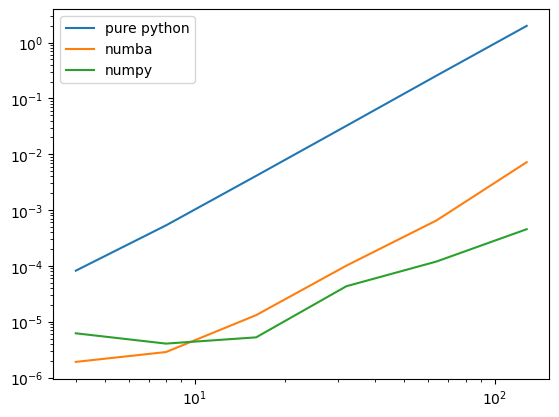

In [41]:
M = np.random.random((8, 8))
print(np.allclose(matrix_power(M, 5), np.linalg.matrix_power(M, 5)),
      np.allclose(matrix_power_numba(M, 5), np.linalg.matrix_power(M, 5)))
prob7()

> **Achtung!** Optimizing code is an important skill, but it is also important to know when to refrain from optimization. The best approach to coding is to write unit tests, implement a solution that works, test and time that solution, *then* (and only then) optimize the solution with profiling techniques. As always, the most important part of the process is choosing the correct algorithm to solve the problem. Don't waste time optimizing a poor algorithm.

## Additional Material

### Other timing techniques

`%time` and `%timeit` are convenient, but some problems need more control. The `time` module (which `%time` uses) times code by hand: `time.time()` returns the number of seconds since the Epoch (https://en.wikipedia.org/wiki/Epoch_(reference_date)#Computing), so take the difference of readings before and after the code runs. The `timeit` module (which `%timeit` uses) runs a code string several times, after optional setup code. (The spec measured 4.20 s for the first loop and 4.88 s for the 200 runs.) Both make it easy to automate timing and save the results; see https://docs.python.org/3.6/library/time.html and https://docs.python.org/3.6/library/timeit.html.

In [42]:
start = time.time()                     # Record the current time.
for i in range(int(1e8)):               # Execute some code.
    pass
end = time.time()                       # Record the time again.
print(end - start)                      # Take the difference (seconds).

import timeit
total = timeit.timeit("for i in range(N): pass", setup="N = int(1e6)", number=200)
print(total, total / 200)               # Total and average time in seconds.

1.0730421543121338


1.14558162499452 0.0057279081249726


### Customizing the profiler

The output of `%prun` can be customized with these options:

| Option | Description |
|---|---|
| `-l <limit>` | Include a limited number of lines in the output. |
| `-s <key>` | Sort the output by call count, cumulative time, function name, etc. |
| `-T <filename>` | Save profile results to a file (results are still printed). |

For example, `%prun -l 3 -s ncalls -T path_profile.txt max_path()` lists the 3 functions with the most calls, then writes the results to `path_profile.txt`. (It is run below without `-T` so no file is written.) See http://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-prun for more details.

In [43]:
%prun -l 3 -s ncalls max_path()

         82354 function calls (49583 primitive calls) in 0.010 seconds

   Ordered by: call count
   List reduced from 81 to 3 due to restriction <3>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    32775    0.001    0.000    0.001    0.000 {built-in method builtins.len}
  32767/1    0.005    0.000    0.007    0.007 1147083602.py:6(path_sum)
    16385    0.001    0.000    0.001    0.000 {built-in method builtins.max}
 